# 03 — Bell States & Entanglement




## Bell state (entanglement)
We create |Φ+> = (|00> + |11>)/√2 and verify measurement correlations.


In [ ]:
!pip install qiskit
!pip install qiskit-aer
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 47.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 1.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=550e70e7c5966625caf03981c3c61917c2a0de9e67dbbda8dcbd4f7c436f1524
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


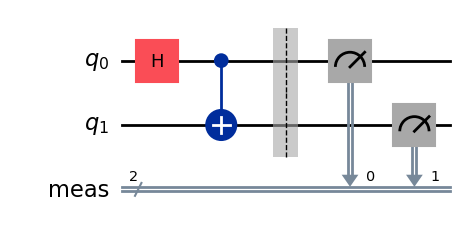

In [ ]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.measure_all()
qc.draw('mpl')


In [ ]:
print(qc)


        ┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1 


In [ ]:

sim = AerSimulator()
counts = sim.run(qc, shots=1000).result().get_counts()
print("Counts:", counts)

Counts: {'11': 505, '00': 495}


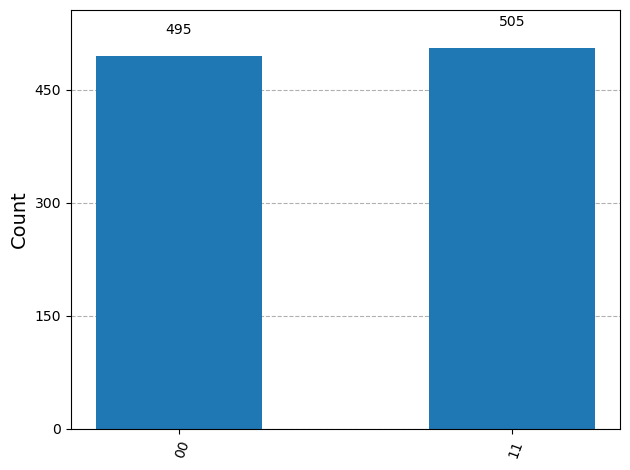

In [ ]:
from qiskit.visualization import plot_histogram
plot_histogram(counts)

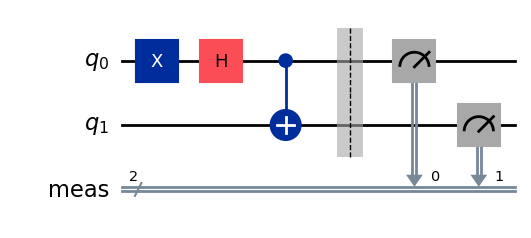

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2)
qc.x(0)
qc.h(0)
qc.cx(0,1)
qc.measure_all()
qc.draw('mpl')

In [ ]:

sim = AerSimulator()
counts = sim.run(qc, shots=1000).result().get_counts()
print("Counts:", counts)

Counts: {'00': 505, '11': 495}


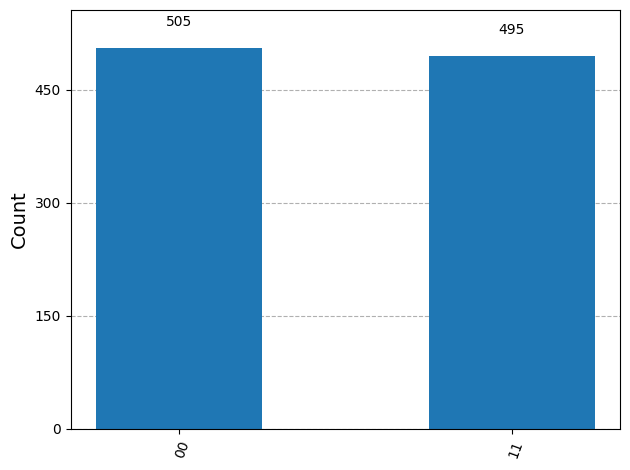

In [ ]:
from qiskit.visualization import plot_histogram
plot_histogram(counts)

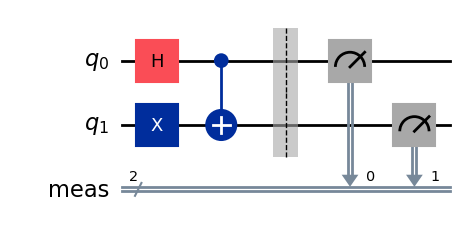

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2)
qc.x(1)
qc.h(0)
qc.cx(0,1)
qc.measure_all()
qc.draw('mpl')

In [ ]:
sim = AerSimulator()
counts = sim.run(qc, shots=1000).result().get_counts()
print("Counts:", counts)

Counts: {'10': 481, '01': 519}


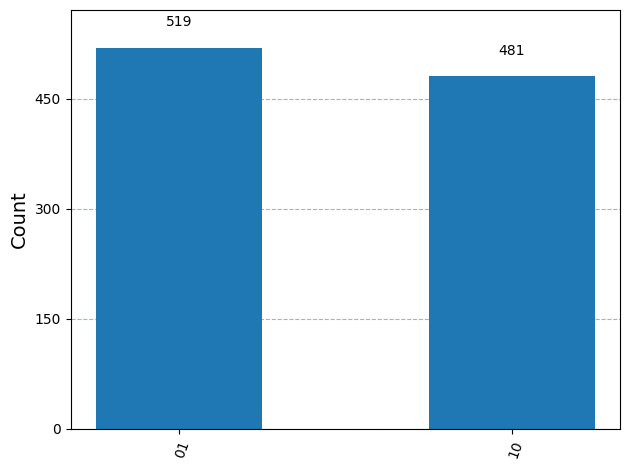

In [ ]:
from qiskit.visualization import plot_histogram
plot_histogram(counts)


### Quick check
You should mostly see **00** and **11** (correlated outcomes).


In [ ]:

# Cirq version
import cirq

q0, q1 = cirq.LineQubit.range(2)
circuit = cirq.Circuit(
    cirq.H(q0),
    cirq.CNOT(q0, q1),
    cirq.measure(q0, q1, key="m"),
)
sim = cirq.Simulator()
result = sim.run(circuit, repetitions=1000)
print(result.histogram(key="m"))


Counter({3: 511, 0: 489})
